# Phase 11.3: MLP neural network

**Owner:** Team lead · **Model:** `MLPClassifier` · **Writes to:** `data/processed/11_3_mlp/`

**What it means:** A multilayer perceptron passes the 60 PCA numbers through two layers of small units. Each layer mixes and bends the one before, so it can learn curved boundaries.

**Key idea:** It is the most flexible of the three, so it is the most likely to memorise the training squares. Early stopping and alpha keep it in check.

Full step-by-step guide and the results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 11.3).

### What we agreed on (same for all three notebooks)
- Train on the **46,408 balanced training squares**, score on the **36,000 validation squares**. The test set is not loaded.
- Pipeline: `StandardScaler` → `PCA(60, random_state=42)` → model.
- Tuning: `GridSearchCV` on train only, `GroupKFold(5)` grouped by photo, `scoring="f1_macro"`.
- Main metric: validation **macro F1** (floor to beat: **0.187**, always answering "none"). Second: **pothole (D40) recall**.

### What to tune

| Setting | Values to try | What it controls |
|---|---|---|
| `hidden_layer_sizes` | (64, 32), (128, 64) | Units per layer: how much the network can learn. |
| `alpha` | 0.0001, 0.001, 0.01 | The penalty that keeps it from memorising. |

**Fixed:** `early_stopping=True`, `random_state=SEED`; balance through `sample_weight` (`compute_sample_weight("balanced", y_tr)`), because `MLPClassifier` has no `class_weight`.

## 1. Setup

Everything shared lives in `ml/training.py`, so this notebook only adds the model:
- `load_data()`: the agreed rows (46,408 balanced training squares, 36,000 validation squares);
- `make_pipeline(clf)`: `StandardScaler` → `PCA(60)` → your model;
- `CV`: `GroupKFold(5)`, folds split by photo;
- `search_table(gs, OUT)`: saves the grid search to `cv_results.csv` and returns the best row;
- `report(...)`: the same evaluation for every model; writes `results.json` and `confusion_matrix.png`.

Don't change `ml/training.py` on your own: a change there changes all three results.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config
from ml.training import CV, load_data, make_pipeline, output_dir, report, search_table

SEED = config.SEED
OUT = output_dir("11_3_mlp")     # this notebook writes only here

data = load_data()                # balanced train + validation; the test set is never loaded
X_tr, y_tr, groups_tr, X_va, y_va = data
print("train", X_tr.shape, "| val", X_va.shape)

train (46408, 1769) | val (36000, 1769)


## 2. Baseline: is it working at all? (Phase 10)

Fit the model once with default settings and score it on validation.

**Check:** clearly above 0.187.

In [2]:
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight

# MLPClassifier has no class_weight, so each square gets a weight instead:
# rare classes (D10, D40) count more, "none" counts less, the same balance as class_weight="balanced"
w_tr = compute_sample_weight("balanced", y_tr)
print("weight per class:", {c: round(float(w_tr[y_tr == i][0]), 2) for i, c in enumerate(config.CLASSES)})

# default network: 1 hidden layer of 100 units, alpha=0.0001; early stopping holds back 10% of train
t = time.perf_counter()
base = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED))
base.fit(X_tr, y_tr, clf__sample_weight=w_tr)     # "clf__" sends the weights to the MLP step only
base_fit = time.perf_counter() - t

mlp = base[-1]
base_f1 = f1_score(y_va, base.predict(X_va), average="macro")
base_train_f1 = f1_score(y_tr, base.predict(X_tr), average="macro")
print(f"fit {base_fit:.0f} s | stopped after {mlp.n_iter_} of {mlp.max_iter} epochs "
      f"| best early-stopping score {mlp.best_validation_score_:.3f}")
print(f"baseline train macro F1 {base_train_f1:.4f} | val macro F1 {base_f1:.4f} | floor 0.187")
assert base_f1 > 0.187, "the baseline does not beat always answering 'none': check data and pipeline first"


weight per class: {'D00': 2.87, 'D10': 5.1, 'D20': 0.71, 'D40': 4.36, 'none': 0.35}


fit 3 s | stopped after 23 of 200 epochs | best early-stopping score 0.410
baseline train macro F1 0.3489 | val macro F1 0.2139 | floor 0.187


## 3. Grid search, on train only

Try every combination in the table above with `GridSearchCV(..., cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True)` and `groups=groups_tr`.

**Check:** one row per combination in `gs.cv_results_`; note how long it took.

In [3]:
pipe = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED))
grid = {"clf__hidden_layer_sizes": [(64, 32), (128, 64)], "clf__alpha": [0.0001, 0.001, 0.01]}

gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True,
                  refit=False)   # the winner is fitted on the full train set in step 5
t = time.perf_counter()
# all 46,408 squares (an MLP fit takes seconds, so no sample is needed);
# GridSearchCV cuts w_tr into the same folds as X_tr, so every fold stays balanced
gs.fit(X_tr, y_tr, groups=groups_tr, clf__sample_weight=w_tr)
grid_secs = time.perf_counter() - t

n_settings = len(gs.cv_results_["params"])
print(f"{n_settings} settings x {CV.get_n_splits()} folds = {n_settings * CV.get_n_splits()} fits "
      f"in {grid_secs / 60:.1f} min")


6 settings x 5 folds = 30 fits in 2.2 min


## 4. Read the search

`cv, best = search_table(gs, OUT)` saves the search and returns the best row. Plot the mean macro F1 per setting.

**Check:** if the best value is at the edge of the grid, add one value beyond it once and note it.

warning check: 30 fold scores, none missing
noise check: fold 1 refit 0.3062 vs grid 0.3152 (diff 0.0090) | spread between the 6 settings 0.0115
best on the grid: {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (128, 64)} | CV macro F1 0.3071 ± 0.0072


best was on the edge; tried [{'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (256, 128)}, {'clf__alpha': 1e-05, 'clf__hidden_layer_sizes': (128, 64)}]: a value beyond the grid won
BEST: {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (256, 128)} | CV macro F1 0.3129 ± 0.0150


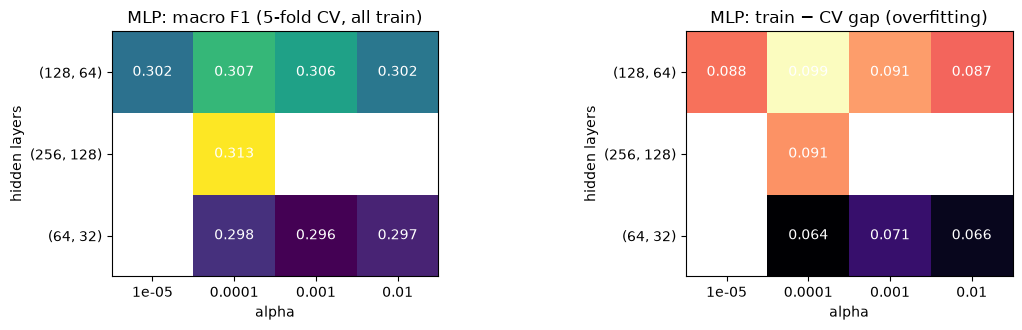

,layers,alpha,mean_test_score,std_test_score,mean_train_score,gap,mean_fit_time
0,"(256, 128)",0.0001,0.3129,0.0150,0.4036,0.0907,24.6677
1,"(128, 64)",0.0001,0.3071,0.0072,0.4056,0.0985,74.6716
2,"(128, 64)",0.0010,0.3055,0.0056,0.3969,0.0914,12.8414
3,"(128, 64)",0.0100,0.3024,0.0014,0.3899,0.0875,19.3188
4,"(128, 64)",0.0000,0.3020,0.0036,0.3904,0.0883,21.2852
5,"(64, 32)",0.0001,0.2980,0.0045,0.3620,0.0641,51.6317
6,"(64, 32)",0.0100,0.2973,0.0048,0.3633,0.0660,23.0382
7,"(64, 32)",0.0010,0.2956,0.0055,0.3663,0.0708,32.0815


In [4]:
from sklearn.base import clone

cv, best = search_table(gs, OUT)          # saves cv_results.csv, returns the best row

# Did the "worker stopped" warning in step 3 cost us anything?
# 1) no fit failed: a failed fit would leave NaN in its fold score
split_cols = [c for c in cv.columns if c.startswith("split") and c.endswith("_test_score")]
n_nan = int(cv[split_cols].isna().sum().sum())
assert n_nan == 0, f"{n_nan} fold scores are missing: some fits failed"
# 2) how much does the score move on its own? Refit the best setting on fold 1 in this process.
#    Same seed, same data, but a different number of parallel workers rounds the sums slightly
#    differently, and MLP training grows that into a different stopping epoch. So expect a
#    small difference, not an exact match (tested: 12 workers repeat exactly; 4 workers differ).
tr_i, te_i = next(CV.split(X_tr, y_tr, groups_tr))
check = clone(pipe).set_params(**best["params"])
check.fit(X_tr[tr_i], y_tr[tr_i], clf__sample_weight=w_tr[tr_i])
redo = f1_score(y_tr[te_i], check.predict(X_tr[te_i]), average="macro")
spread = cv["mean_test_score"].max() - cv["mean_test_score"].min()
print(f"warning check: {len(cv) * len(split_cols)} fold scores, none missing")
print(f"noise check: fold 1 refit {redo:.4f} vs grid {best['split0_test_score']:.4f} "
      f"(diff {abs(redo - best['split0_test_score']):.4f}) | spread between the 6 settings {spread:.4f}")

print("best on the grid:", best["params"], f"| CV macro F1 {best['mean_test_score']:.4f} "
      f"± {best['std_test_score']:.4f}")

# Edge check: if the best size or alpha is the largest/smallest value tried, try one value beyond it once.
h_b, a_b = best["params"]["clf__hidden_layer_sizes"], best["params"]["clf__alpha"]
beyond = []
if h_b == (128, 64):
    beyond.append({"clf__hidden_layer_sizes": [(256, 128)], "clf__alpha": [a_b]})
elif h_b == (64, 32):
    beyond.append({"clf__hidden_layer_sizes": [(32, 16)], "clf__alpha": [a_b]})
if a_b == max(grid["clf__alpha"]):
    beyond.append({"clf__hidden_layer_sizes": [h_b], "clf__alpha": [a_b * 10]})
elif a_b == min(grid["clf__alpha"]):
    beyond.append({"clf__hidden_layer_sizes": [h_b], "clf__alpha": [a_b / 10]})

edge_note = "best is inside the grid: no extra values needed"
if beyond:
    gs2 = GridSearchCV(pipe, beyond, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True,
                       refit=False)
    t = time.perf_counter()
    gs2.fit(X_tr, y_tr, groups=groups_tr, clf__sample_weight=w_tr)
    grid_secs += time.perf_counter() - t
    extra = pd.DataFrame(gs2.cv_results_).assign(extra=True)
    assert not extra[split_cols].isna().any().any(), "an extra fit failed"
    cv = pd.concat([cv.assign(extra=False), extra], ignore_index=True)
    cv["rank_test_score"] = cv["mean_test_score"].rank(ascending=False, method="min").astype(int)
    cv.to_csv(OUT / "cv_results.csv", index=False)
    new_best = cv.loc[cv["mean_test_score"].idxmax()]
    edge_note = (f"best was on the edge; tried {[p for p in gs2.cv_results_['params']]}: "
                 + ("a value beyond the grid won" if new_best["extra"] else "the grid's best still wins"))
    best = new_best
print(edge_note)
print("BEST:", best["params"], f"| CV macro F1 {best['mean_test_score']:.4f} ± {best['std_test_score']:.4f}")

cv["layers"] = cv["param_clf__hidden_layer_sizes"].astype(str)
cv["alpha"] = cv["param_clf__alpha"].astype(float)
cv["gap"] = cv["mean_train_score"] - cv["mean_test_score"]
heat = cv.pivot_table(index="layers", columns="alpha", values="mean_test_score")
gap = cv.pivot_table(index="layers", columns="alpha", values="gap")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, table, title, cmap in [(axes[0], heat, "macro F1 (5-fold CV, all train)", "viridis"),
                               (axes[1], gap, "train − CV gap (overfitting)", "magma")]:
    ax.imshow(table, cmap=cmap)
    ax.set(xticks=range(table.shape[1]), xticklabels=table.columns, yticks=range(table.shape[0]),
           yticklabels=table.index, xlabel="alpha", ylabel="hidden layers", title=f"MLP: {title}")
    for (i, j), v in np.ndenumerate(table.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white")
fig.tight_layout()
fig.savefig(OUT / "grid_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

cols = ["layers", "alpha", "mean_test_score", "std_test_score", "mean_train_score", "gap", "mean_fit_time"]
cv.sort_values("mean_test_score", ascending=False)[cols].round(4).reset_index(drop=True)


## 5. Final model, scored on validation

`report(pipe, data, OUT, "11.3 MLP", best, train_seconds)` writes `results.json` and `confusion_matrix.png`.

**Check:** read the D40 row of the confusion matrix: where do the missed potholes go?

## 6. Plot the loss curve

Plot `loss_curve_` and `validation_scores_`: the loss should fall, then flatten.

## 7. Diagnose before changing anything (Phase 12)

Train − validation gap above 0.15: overfitting. Both low and close: underfitting. Change **one** thing at a time, keep it only if validation macro F1 goes up, and log every try (also the failed ones).

## 8. Save and hand in

`joblib.dump(...)` the final pipeline to `OUT / "best_pipeline.joblib"`. Then import `results.json` in the Results sheet tab of the team plan, add your observations and download the PDF.